# World-indepth — MapAnything Colab smoke test + View Budget Challenge

**Purpose:** run the first real MapAnything reconstruction on the ETH3D `pipes` multi-view indoor scene using a Colab GPU.

This notebook:
1. Pins the World-indepth repository, MapAnything source and Apache checkpoint.
2. Downloads the official ETH3D Pipes undistorted image archive.
3. Creates a deterministic 8-input / 4-held-out split from 14 images.
4. Runs a **two-view smoke test first**.
5. Optionally runs the full **1 / 2 / 3 / 5 / 8 view** budget experiment.
6. Saves predictions, camera data, confidence, masks, a compact point cloud and run metadata to a ZIP for download.

**Do not run the full experiment cell unless the two-view smoke test succeeds.** No photos or results are uploaded to GitHub. Colab's `/content` storage is temporary, so download the ZIP before ending the session.

Dataset: [ETH3D Pipes](https://eth3d.ethz.ch/datasets), 14 indoor images. ETH3D data is licensed **CC BY-NC-SA 4.0**; this is non-commercial research data and any redistribution must comply with attribution and share-alike terms.

**Model:** `facebook/map-anything-apache` (Apache-2.0 checkpoint). This notebook does inference only; it does not train or fine-tune the model.

**How to run:** open [Google Colab](https://colab.research.google.com/) → **File → Upload notebook** → select this downloaded `.ipynb`. Then choose **Runtime → Change runtime type → GPU** and execute from the first cell downward. Run the full-budget cell only after the smoke-test cell prints `TWO-VIEW SMOKE TEST PASSED`.

The 4-image held-out split below is a **custom within-scene holdout**, not ETH3D's official benchmark test split. These images are reserved from MapAnything inference; this notebook does not claim camera registration or held-out image metrics.


## A. Pin the project code and record the runtime

Run cells in order. This checks out a fixed, published World-indepth commit rather than silently following a moving branch head.

In [1]:
import os
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

from pathlib import Path
import datetime as dt
import hashlib
import json
import platform
import re
import shutil
import subprocess
import sys
import time
import urllib.request
import zipfile
import gc
import struct

REPO_URL = "https://github.com/HimanshuPathak2725/World-indepth.git"
REPO_BRANCH = "feat/view-budget-challenge"
REPO_COMMIT = "eef9bb27b02ae369027ab18deadc0bfc0e10ac7a"
REPO_DIR = Path("/content/World-indepth")

if not REPO_DIR.exists():
    subprocess.run(
        ["git", "clone", "--filter=blob:none", "--branch", REPO_BRANCH, REPO_URL, str(REPO_DIR)],
        check=True,
    )

subprocess.run(["git", "fetch", "origin", REPO_BRANCH], cwd=REPO_DIR, check=True)
subprocess.run(["git", "checkout", "--detach", REPO_COMMIT], cwd=REPO_DIR, check=True)

REPO_SHA = subprocess.check_output(
    ["git", "rev-parse", "HEAD"], cwd=REPO_DIR, text=True
).strip()
if REPO_SHA != REPO_COMMIT:
    raise RuntimeError(f"Repository SHA mismatch: expected {REPO_COMMIT}, got {REPO_SHA}")

LAB_DIR = REPO_DIR / "spatial-reconstruction-lab"
sys.path.insert(0, str(LAB_DIR))

from dataset import validate_manifest, DatasetError

print({
    "repository": REPO_URL,
    "branch": REPO_BRANCH,
    "commit": REPO_SHA,
    "python": sys.version,
    "platform": platform.platform(),
    "recorded_at_utc": dt.datetime.now(dt.timezone.utc).isoformat(),
})

{'repository': 'https://github.com/HimanshuPathak2725/World-indepth.git', 'branch': 'feat/view-budget-challenge', 'commit': 'eef9bb27b02ae369027ab18deadc0bfc0e10ac7a', 'python': '3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]', 'platform': 'Linux-6.6.159+-x86_64-with-glibc2.39', 'recorded_at_utc': '2026-11-15T17:37:13.586628+00:00'}


## B. GPU preflight

In Colab choose **Runtime → Change runtime type → T4 GPU** (or another available GPU). GPU allocation is not guaranteed. This cell stops instead of silently running MapAnything on CPU.

In [2]:
import torch
import shutil

if not torch.cuda.is_available():
    raise RuntimeError(
        "No CUDA GPU is attached. In Colab select Runtime > Change runtime type > GPU, "
        "save, then rerun the notebook."
    )

DEVICE = "cuda"
gpu = torch.cuda.get_device_properties(0)
free_vram, total_vram = torch.cuda.mem_get_info(0)

try:
    import psutil
    system_ram_gib = round(psutil.virtual_memory().total / 2**30, 2)
except Exception:
    system_ram_gib = None

disk = shutil.disk_usage("/content")
BF16_SUPPORTED = bool(torch.cuda.is_bf16_supported())
AMP_DTYPE_REQUESTED = "bf16"  # MapAnything falls back to fp16 if BF16 is unsupported.
AMP_DTYPE_EFFECTIVE = "bf16" if BF16_SUPPORTED else "fp16"

GPU_INFO = {
    "gpu": gpu.name,
    "total_vram_gib": round(total_vram / 2**30, 2),
    "free_vram_gib": round(free_vram / 2**30, 2),
    "cuda_version": torch.version.cuda,
    "torch_version": torch.__version__,
    "bf16_supported": BF16_SUPPORTED,
    "amp_dtype_requested": AMP_DTYPE_REQUESTED,
    "amp_dtype_effective": AMP_DTYPE_EFFECTIVE,
    "system_ram_gib": system_ram_gib,
    "disk_free_gib": round(disk.free / 2**30, 2),
}
print(json.dumps(GPU_INFO, indent=2))

if free_vram < 7 * 2**30:
    raise RuntimeError(
        "Less than 7 GiB free GPU memory is available. Restart the Colab runtime "
        "or select a GPU with more free VRAM before loading the checkpoint."
    )
if total_vram < 12 * 2**30:
    print("WARNING: GPU has less than 12 GiB total VRAM. Even the two-view smoke test may OOM.")

{
  "gpu": "Tesla T4",
  "total_vram_gib": 14.56,
  "free_vram_gib": 14.46,
  "cuda_version": "13.0",
  "torch_version": "2.14.1+cu130",
  "bf16_supported": true,
  "amp_dtype_requested": "bf16",
  "amp_dtype_effective": "bf16",
  "system_ram_gib": 12.67,
  "disk_free_gib": 112.54
}


## C. Install the pinned MapAnything source

The upstream README recommends Python 3.12 and `pip install -e .`. Its base `pyproject.toml` does not pin PyTorch/CUDA, so this installs the base package dependencies while retaining Colab's preinstalled Torch/CUDA build.

The checkpoint is separately pinned to a Hugging Face commit. Optional external-model extras are not installed.

In [4]:
UPSTREAM_URL = "https://github.com/facebookresearch/map-anything.git"
UPSTREAM_COMMIT = "3d10cf7a3016fc0f9bb13a071ee66c47b10be0d9"
UPSTREAM_DIR = Path("/content/map-anything")

if not UPSTREAM_DIR.exists():
    subprocess.run(["git", "clone", UPSTREAM_URL, str(UPSTREAM_DIR)], check=True)

subprocess.run(
    ["git", "fetch", "origin", UPSTREAM_COMMIT],
    cwd=UPSTREAM_DIR,
    check=True,
)
subprocess.run(
    ["git", "checkout", "--detach", UPSTREAM_COMMIT],
    cwd=UPSTREAM_DIR,
    check=True,
)

resolved_source_sha = subprocess.check_output(
    ["git", "rev-parse", "HEAD"], cwd=UPSTREAM_DIR, text=True
).strip()
if resolved_source_sha != UPSTREAM_COMMIT:
    raise RuntimeError("MapAnything source checkout is not the pinned commit")

TORCH_BEFORE_INSTALL = torch.__version__
CUDA_BEFORE_INSTALL = torch.version.cuda

# Install upstream base dependencies
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-e", str(UPSTREAM_DIR)],
    check=True,
)

# Ensure the installed package is discoverable
sys.path.insert(0, str(UPSTREAM_DIR))

import importlib
import mapanything
from mapanything.models import MapAnything
from mapanything.utils.image import load_images
from huggingface_hub import HfApi

if torch.__version__ != TORCH_BEFORE_INSTALL or torch.version.cuda != CUDA_BEFORE_INSTALL:
    raise RuntimeError(
        "The installation changed the active Torch/CUDA version. Restart the runtime, "
        "rerun GPU preflight, then rerun installation before continuing."
    )

MODEL_ID = "facebook/map-anything-apache"
MODEL_REVISION = "00f9c245bbcb60522d1ed7f9e9d88462c6e3f38a"

model_info = HfApi().model_info(MODEL_ID, revision=MODEL_REVISION)
if model_info.sha != MODEL_REVISION:
    raise RuntimeError(
        f"Checkpoint SHA mismatch: expected {MODEL_REVISION}, got {model_info.sha}"
    )

print({
    "mapanything_import": mapanything.__file__,
    "upstream_source_commit": resolved_source_sha,
    "checkpoint_id": MODEL_ID,
    "checkpoint_revision": model_info.sha,
    "checkpoint_license": (getattr(model_info.card_data, "license", None) if model_info.card_data else None),
    "torch": torch.__version__,
    "torchvision": __import__("torchvision").__version__,
})

{'mapanything_import': '/content/map-anything/mapanything/__init__.py', 'upstream_source_commit': '3d10cf7a3016fc0f9bb13a071ee66c47b10be0d9', 'checkpoint_id': 'facebook/map-anything-apache', 'checkpoint_revision': '00f9c245bbcb60522d1ed7f9e9d88462c6e3f38a', 'checkpoint_license': 'apache-2.0', 'torch': '2.14.1+cu130', 'torchvision': '0.29.1+cu130'}


## D. Download and inspect the ETH3D Pipes scene

The ETH3D page lists Pipes as a **14-image indoor high-resolution multi-view training scene**. The undistorted JPEG archive is about 0.1 GB. We display a contact sheet before assigning inputs and held-out images so you can inspect filename order.

In [5]:

PIPES_URL = "https://eth3d.ethz.ch/data/pipes_dslr_undistorted.7z"
ARCHIVE_PATH = Path("/content/pipes_dslr_undistorted.7z")
PIPES_DIR = Path("/content/eth3d_pipes")

subprocess.run(["apt-get", "-qq", "install", "-y", "p7zip-full"], check=True)

if ARCHIVE_PATH.exists():
    archive_test = subprocess.run(
        ["7z", "t", str(ARCHIVE_PATH)],
        stdout=subprocess.DEVNULL,
        stderr=subprocess.DEVNULL,
    )
    if archive_test.returncode != 0:
        ARCHIVE_PATH.unlink()

if not ARCHIVE_PATH.exists():
    print("Downloading ETH3D Pipes undistorted images...")
    urllib.request.urlretrieve(PIPES_URL, ARCHIVE_PATH)

def natural_key(path):
    return [
        int(part) if part.isdigit() else part.lower()
        for part in re.split(r"(\d+)", path.name)
    ]

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}

def discover_images(root):
    return sorted(
        [p for p in root.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS],
        key=natural_key,
    )

if PIPES_DIR.exists() and len(discover_images(PIPES_DIR)) != 14:
    shutil.rmtree(PIPES_DIR)

if not PIPES_DIR.exists():
    PIPES_DIR.mkdir(parents=True, exist_ok=True)
    subprocess.run(
        ["7z", "x", str(ARCHIVE_PATH), f"-o{PIPES_DIR}", "-y"],
        check=True,
    )

all_image_paths = discover_images(PIPES_DIR)

print("Images found:", len(all_image_paths))
for i, image_path in enumerate(all_image_paths):
    print(f"{i:02d}: {image_path.relative_to(PIPES_DIR)}")

if len(all_image_paths) != 14:
    raise RuntimeError(
        f"Expected the 14 ETH3D Pipes images listed by the official dataset page, "
        f"but found {len(all_image_paths)}. Inspect the extraction tree before proceeding."
    )


Images found: 14
00: pipes/images/dslr_images_undistorted/DSC_0634.JPG
01: pipes/images/dslr_images_undistorted/DSC_0635.JPG
02: pipes/images/dslr_images_undistorted/DSC_0636.JPG
03: pipes/images/dslr_images_undistorted/DSC_0637.JPG
04: pipes/images/dslr_images_undistorted/DSC_0638.JPG
05: pipes/images/dslr_images_undistorted/DSC_0639.JPG
06: pipes/images/dslr_images_undistorted/DSC_0640.JPG
07: pipes/images/dslr_images_undistorted/DSC_0641.JPG
08: pipes/images/dslr_images_undistorted/DSC_0642.JPG
09: pipes/images/dslr_images_undistorted/DSC_0643.JPG
10: pipes/images/dslr_images_undistorted/DSC_0644.JPG
11: pipes/images/dslr_images_undistorted/DSC_0645.JPG
12: pipes/images/dslr_images_undistorted/DSC_0646.JPG
13: pipes/images/dslr_images_undistorted/DSC_0647.JPG


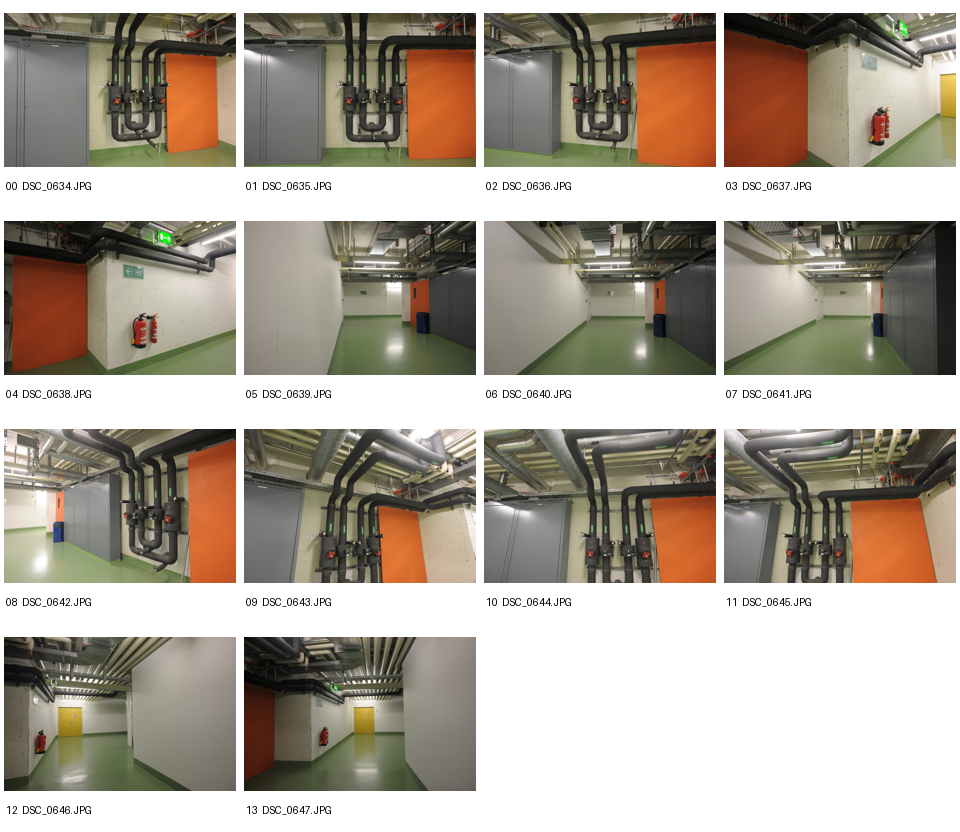

In [6]:
# Contact sheet: inspect the natural filename order before accepting the default split.
from PIL import Image, ImageOps, ImageDraw
from IPython.display import display

thumb_w, thumb_h = 240, 180
label_h = 28
cols = 4
rows = (len(all_image_paths) + cols - 1) // cols
sheet = Image.new("RGB", (cols * thumb_w, rows * (thumb_h + label_h)), "white")
draw = ImageDraw.Draw(sheet)

for index, image_path in enumerate(all_image_paths):
    with Image.open(image_path) as source:
        image = ImageOps.exif_transpose(source).convert("RGB")
        image.thumbnail((thumb_w - 8, thumb_h - 8))
    x = (index % cols) * thumb_w
    y = (index // cols) * (thumb_h + label_h)
    sheet.paste(image, (x + (thumb_w - image.width)//2, y + (thumb_h - image.height)//2))
    draw.text((x + 6, y + thumb_h), f"{index:02d}  {image_path.name[:30]}", fill="black")

display(sheet)

### Create the private scene manifest

Default split below uses the naturally sorted filename order as an **ordinal capture-order proxy**; it does not claim known camera positions. Four held-out images are interleaved across the sequence. Eight input images are spread across the remaining sequence.

If the contact sheet suggests the filename order is not a sensible capture sequence, stop here and adjust the two index lists manually. Two other images are left unused.

ETH3D's official site states the dataset licence is **CC BY-NC-SA 4.0**. Do not use this dataset for commercial work or republish it without complying with the licence.

In [7]:
import numpy as np
from PIL import Image

# Default for 14 naturally sorted ETH3D Pipes images.
# Edit these after inspecting the contact sheet if needed.
INPUT_SOURCE_INDICES = [0, 2, 4, 6, 7, 9, 11, 13]
HELDOUT_SOURCE_INDICES = [1, 5, 8, 12]

if len(INPUT_SOURCE_INDICES) != 8 or len(HELDOUT_SOURCE_INDICES) != 4:
    raise ValueError("Expected exactly 8 input and 4 held-out source indices")
if len(set(INPUT_SOURCE_INDICES + HELDOUT_SOURCE_INDICES)) != 12:
    raise ValueError("Input and held-out source indices must be unique")
if any(i < 0 or i >= len(all_image_paths) for i in INPUT_SOURCE_INDICES + HELDOUT_SOURCE_INDICES):
    raise ValueError("A source index is outside the extracted image list")

SCENE_ID = "eth3d-pipes"
SCENE_ROOT = Path("/content/private_scene") / SCENE_ID
IMAGE_DIR = SCENE_ROOT / "images"
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

views = []
held_out = []

def copy_and_record(source_index, split, ordinal):
    source_path = all_image_paths[source_index]
    target_name = f"{split}_{ordinal:02d}{source_path.suffix.lower()}"
    target_path = IMAGE_DIR / target_name
    shutil.copy2(source_path, target_path)

    with Image.open(target_path) as image:
        image.verify()
    with Image.open(target_path) as image:
        width, height = image.size

    record = {
        "id": f"{split}-{ordinal:02d}",
        "filename": f"images/{target_name}",
        "capture_order": int(source_index),
        "source_filename": str(source_path.relative_to(PIPES_DIR)),
        "source_index": int(source_index),
        "sha256": hashlib.sha256(target_path.read_bytes()).hexdigest(),
        "width": int(width),
        "height": int(height),
    }
    return record

for ordinal, source_index in enumerate(INPUT_SOURCE_INDICES):
    views.append(copy_and_record(source_index, "input", ordinal))

for ordinal, source_index in enumerate(HELDOUT_SOURCE_INDICES):
    held_out.append(copy_and_record(source_index, "heldout", ordinal))

manifest = {
    "schema_version": 1,
    "scene_id": SCENE_ID,
    "origin": {
        "description": "ETH3D high-resolution multi-view Pipes training scene",
        "dataset_url": "https://eth3d.ethz.ch/datasets",
        "archive_url": PIPES_URL,
        "license": "CC BY-NC-SA 4.0",
        "commercial_use": False,
        "split_policy": "Four held-out views interleaved across natural filename order; eight inputs sampled across remaining images.",
    },
    "views": views,
    "held_out": held_out,
}

manifest["origin"]["archive_sha256"] = hashlib.sha256(ARCHIVE_PATH.read_bytes()).hexdigest()
MANIFEST_PATH = SCENE_ROOT / "manifest.json"
MANIFEST_PATH.write_text(json.dumps(manifest, indent=2) + "\n")

validate_manifest(manifest, SCENE_ROOT)

print(json.dumps({
    "manifest": str(MANIFEST_PATH),
    "inputs": [{"id": v["id"], "source_index": v["source_index"], "file": v["source_filename"]} for v in views],
    "held_out": [{"id": v["id"], "source_index": v["source_index"], "file": v["source_filename"]} for v in held_out],
    "unused_source_indices": sorted(set(range(len(all_image_paths))) - set(INPUT_SOURCE_INDICES + HELDOUT_SOURCE_INDICES)),
    "license": manifest["origin"]["license"],
}, indent=2))

{
  "manifest": "/content/private_scene/eth3d-pipes/manifest.json",
  "inputs": [
    {
      "id": "input-00",
      "source_index": 0,
      "file": "pipes/images/dslr_images_undistorted/DSC_0634.JPG"
    },
    {
      "id": "input-01",
      "source_index": 2,
      "file": "pipes/images/dslr_images_undistorted/DSC_0636.JPG"
    },
    {
      "id": "input-02",
      "source_index": 4,
      "file": "pipes/images/dslr_images_undistorted/DSC_0638.JPG"
    },
    {
      "id": "input-03",
      "source_index": 6,
      "file": "pipes/images/dslr_images_undistorted/DSC_0640.JPG"
    },
    {
      "id": "input-04",
      "source_index": 7,
      "file": "pipes/images/dslr_images_undistorted/DSC_0641.JPG"
    },
    {
      "id": "input-05",
      "source_index": 9,
      "file": "pipes/images/dslr_images_undistorted/DSC_0643.JPG"
    },
    {
      "id": "input-06",
      "source_index": 11,
      "file": "pipes/images/dslr_images_undistorted/DSC_0645.JPG"
    },
    {
      "id": "in

## E. Deterministic nested view budgets

The repository's current dataset helper selects capture-order prefixes. For this notebook we explicitly define a **nested, spread-out ordinal selection** over the eight input candidates. It uses natural filename order only as a proxy; it does not use known camera poses.

The budgets are nested: each smaller budget is a subset of the next larger budget. Held-out IDs are never selectable.

In [8]:
# Candidate positions are ordered by capture order.
NESTED_POSITIONS = {
    1: [3],
    2: [1, 3],
    3: [1, 3, 5],
    5: [0, 1, 3, 5, 7],
    8: list(range(8)),
}

def select_budget_views(budget):
    if budget not in NESTED_POSITIONS:
        raise ValueError(f"Unsupported budget: {budget}")
    selected = [manifest["views"][i] for i in NESTED_POSITIONS[budget]]
    selected = sorted(selected, key=lambda item: (item["capture_order"], item["id"]))
    selected_ids = {item["id"] for item in selected}
    heldout_ids = {item["id"] for item in manifest["held_out"]}
    if len(selected) != budget or selected_ids & heldout_ids:
        raise RuntimeError("View selection count or held-out leakage check failed")
    return selected

# Prove that the sets are nested.
previous = set()
for budget in (1, 2, 3, 5, 8):
    selected = select_budget_views(budget)
    current = {item["id"] for item in selected}
    assert previous.issubset(current)
    previous = current
    print(f"{budget} views:", [(item["id"], item["source_filename"]) for item in selected])

1 views: [('input-03', 'pipes/images/dslr_images_undistorted/DSC_0640.JPG')]
2 views: [('input-01', 'pipes/images/dslr_images_undistorted/DSC_0636.JPG'), ('input-03', 'pipes/images/dslr_images_undistorted/DSC_0640.JPG')]
3 views: [('input-01', 'pipes/images/dslr_images_undistorted/DSC_0636.JPG'), ('input-03', 'pipes/images/dslr_images_undistorted/DSC_0640.JPG'), ('input-05', 'pipes/images/dslr_images_undistorted/DSC_0643.JPG')]
5 views: [('input-00', 'pipes/images/dslr_images_undistorted/DSC_0634.JPG'), ('input-01', 'pipes/images/dslr_images_undistorted/DSC_0636.JPG'), ('input-03', 'pipes/images/dslr_images_undistorted/DSC_0640.JPG'), ('input-05', 'pipes/images/dslr_images_undistorted/DSC_0643.JPG'), ('input-07', 'pipes/images/dslr_images_undistorted/DSC_0647.JPG')]
8 views: [('input-00', 'pipes/images/dslr_images_undistorted/DSC_0634.JPG'), ('input-01', 'pipes/images/dslr_images_undistorted/DSC_0636.JPG'), ('input-02', 'pipes/images/dslr_images_undistorted/DSC_0638.JPG'), ('input-03',

## F. Load and validate model outputs

MapAnything's image-only inference API returns a list of prediction dictionaries, one per input view. The official README documents world/camera point maps, depth, ray directions, intrinsics, camera poses, confidence, masks and denormalized input RGB.

The helpers below explicitly move CUDA tensors to CPU before NumPy conversion. This avoids a common failure in the earlier notebook, which called `np.asarray()` directly on GPU tensors.

In [9]:
import numpy as np
import torch

REQUIRED_OUTPUTS = {
    "pts3d",
    "pts3d_cam",
    "intrinsics",
    "camera_poses",
    "conf",
    "mask",
    "img_no_norm",
}
DOCUMENTED_OPTIONAL_OUTPUTS = {
    "depth_z",
    "depth_along_ray",
    "ray_directions",
    "cam_trans",
    "cam_quats",
    "non_ambiguous_mask",
    "non_ambiguous_mask_logits",
    "metric_scaling_factor",
}

def to_numpy(value):
    if torch.is_tensor(value):
        return value.detach().cpu().numpy()
    if isinstance(value, np.ndarray):
        return value
    if isinstance(value, (int, float, bool, np.number, list, tuple)):
        try:
            return np.asarray(value)
        except Exception:
            return None
    return None

def mask_to_hw(mask_array):
    mask_array = np.asarray(mask_array).astype(bool)
    if mask_array.ndim == 4 and mask_array.shape[-1] == 1:
        mask_array = mask_array[..., 0]
    if mask_array.ndim != 3:
        raise ValueError(f"Expected mask (B,H,W) or (B,H,W,1), got {mask_array.shape}")
    return mask_array

def validate_predictions(predictions, expected_view_count):
    if not isinstance(predictions, (list, tuple)) or len(predictions) != expected_view_count:
        raise ValueError(
            f"Expected {expected_view_count} prediction dictionaries, "
            f"got {type(predictions).__name__} with length "
            f"{len(predictions) if hasattr(predictions, '__len__') else 'N/A'}"
        )

    summaries = []
    for view_index, prediction in enumerate(predictions):
        if not isinstance(prediction, dict):
            raise TypeError(f"Prediction {view_index} is not a dictionary")

        missing = REQUIRED_OUTPUTS - set(prediction)
        if missing:
            raise ValueError(f"Prediction {view_index} missing required outputs: {sorted(missing)}")

        points = to_numpy(prediction["pts3d"])
        points_cam = to_numpy(prediction["pts3d_cam"])
        intrinsics = to_numpy(prediction["intrinsics"])
        poses = to_numpy(prediction["camera_poses"])
        confidence = to_numpy(prediction["conf"])
        mask = mask_to_hw(to_numpy(prediction["mask"]))
        rgb = to_numpy(prediction["img_no_norm"])

        if points.ndim != 4 or points.shape[-1] != 3:
            raise ValueError(f"pts3d must be (B,H,W,3), got {points.shape}")
        if points_cam.shape != points.shape:
            raise ValueError(f"pts3d_cam shape {points_cam.shape} != pts3d {points.shape}")
        if confidence.shape[:3] != points.shape[:3]:
            raise ValueError(f"conf shape {confidence.shape} does not align with pts3d {points.shape}")
        if mask.shape != points.shape[:3]:
            raise ValueError(f"mask shape {mask.shape} does not align with pts3d {points.shape}")
        if rgb.shape != points.shape:
            raise ValueError(f"img_no_norm shape {rgb.shape} does not align with pts3d {points.shape}")
        if intrinsics.shape[-2:] != (3, 3):
            raise ValueError(f"intrinsics must end in (3,3), got {intrinsics.shape}")
        if poses.shape[-2:] != (4, 4):
            raise ValueError(f"camera_poses must end in (4,4), got {poses.shape}")

        valid = mask & np.isfinite(points).all(axis=-1)
        if not valid.any():
            raise ValueError(f"Prediction {view_index} has no finite valid 3D points")
        if not np.isfinite(intrinsics).all() or not np.isfinite(poses).all():
            raise ValueError(f"Prediction {view_index} has non-finite camera calibration/poses")

        valid_conf = confidence[valid]
        if valid_conf.size == 0 or not np.isfinite(valid_conf).all():
            raise ValueError(f"Prediction {view_index} has no finite valid confidence values")

        summaries.append({
            "view_index": view_index,
            "shape": list(points.shape),
            "valid_points": int(valid.sum()),
            "confidence_min": float(valid_conf.min()),
            "confidence_mean": float(valid_conf.mean()),
            "confidence_max": float(valid_conf.max()),
            "available_keys": sorted(prediction.keys()),
            "missing_documented_optional_keys": sorted(DOCUMENTED_OPTIONAL_OUTPUTS - set(prediction)),
        })
    return summaries

print("Output validation helpers ready.")

Output validation helpers ready.


## G. Load the pinned Apache checkpoint

Model loading is a separate step from inference. The model is loaded once and reused across budgets, avoiding repeated checkpoint downloads and initialization.

In [10]:
MODEL_LOAD_START = time.perf_counter()
model = MapAnything.from_pretrained(
    MODEL_ID,
    revision=MODEL_REVISION,
).to(DEVICE)
model.eval()
torch.cuda.synchronize()
MODEL_LOAD_SECONDS = time.perf_counter() - MODEL_LOAD_START

print({
    "model_id": MODEL_ID,
    "checkpoint_revision": MODEL_REVISION,
    "device": DEVICE,
    "model_load_seconds": round(MODEL_LOAD_SECONDS, 3),
    "gpu_memory_allocated_gib": round(torch.cuda.memory_allocated() / 2**30, 3),
    "gpu_memory_reserved_gib": round(torch.cuda.memory_reserved() / 2**30, 3),
})

config.json:   0%|          | 0.00/5.78k [00:00<?, ?B/s]

Loading pretrained dinov2_vitg14 from torch hub
Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


model.safetensors: reconstructing file:   0%|          |  0.00B / 4.91GB            

model.safetensors: downloading bytes:           |  0.00B            

{'model_id': 'facebook/map-anything-apache', 'checkpoint_revision': '00f9c245bbcb60522d1ed7f9e9d88462c6e3f38a', 'device': 'cuda', 'model_load_seconds': 274.444, 'gpu_memory_allocated_gib': 4.577, 'gpu_memory_reserved_gib': 4.582}


## H. Run the two-view smoke test first

This cell uses exactly two input views. It writes results only after validating model outputs. On CUDA OOM or another inference error, it raises visibly; it does not claim success or automatically start the full matrix.

In [11]:
RESULTS_DIR = Path("/content/world_indepth_results") / SCENE_ID
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
(RESULTS_DIR / "scene_manifest.json").write_text(json.dumps(manifest, indent=2) + "\n")

def current_gpu_memory():
    free_bytes, total_bytes = torch.cuda.mem_get_info(0)
    return {
        "allocated_bytes": int(torch.cuda.memory_allocated(0)),
        "reserved_bytes": int(torch.cuda.memory_reserved(0)),
        "free_bytes": int(free_bytes),
        "total_bytes": int(total_bytes),
    }

def save_prediction_arrays(predictions, output_dir):
    arrays = {}
    shapes = {}
    unpersisted = {}

    for view_index, prediction in enumerate(predictions):
        for key, value in prediction.items():
            array = to_numpy(value)
            if array is None:
                unpersisted[f"view_{view_index}__{key}"] = str(type(value))
                continue
            if array.dtype == object:
                unpersisted[f"view_{view_index}__{key}"] = "object dtype skipped"
                continue
            name = f"view_{view_index:02d}__{key}"
            arrays[name] = array
            shapes[name] = list(array.shape)

    if not arrays:
        raise RuntimeError("No numeric model outputs could be serialized")
    np.savez_compressed(output_dir / "predictions.npz", **arrays)
    return {"saved_arrays": sorted(arrays), "array_shapes": shapes, "unpersisted": unpersisted}

def write_compact_cloud(predictions, output_path):
    # WIPCLD01 = 8-byte magic + uint32 point count + records of float32 XYZ and uint8 RGB.
    record_dtype = np.dtype([("xyz", "<f4", (3,)), ("rgb", "u1", (3,))], align=False)
    if record_dtype.itemsize != 15:
        raise RuntimeError(f"Unexpected WIPCLD01 record size: {record_dtype.itemsize}")

    output_path.parent.mkdir(parents=True, exist_ok=True)
    total_points = 0

    with output_path.open("wb") as output:
        output.write(b"WIPCLD01")
        output.write(struct.pack("<I", 0))  # patched with final count after streaming records

        for prediction in predictions:
            points = to_numpy(prediction["pts3d"])
            rgb = to_numpy(prediction["img_no_norm"])
            mask = mask_to_hw(to_numpy(prediction["mask"]))

            if points.shape[0] != 1:
                raise ValueError("Expected batch size 1 for each per-view prediction")
            xyz = points[0]
            colors = rgb[0]

            if colors.max(initial=0) <= 1.5:
                colors = colors * 255.0
            colors = np.clip(colors, 0, 255).astype(np.uint8)

            valid = mask[0] & np.isfinite(xyz).all(axis=-1)
            valid &= np.isfinite(colors).all(axis=-1)
            if not valid.any():
                continue

            records = np.empty(int(valid.sum()), dtype=record_dtype)
            records["xyz"] = xyz[valid].astype(np.float32, copy=False)
            records["rgb"] = colors[valid]
            records.tofile(output)
            total_points += len(records)

        if total_points == 0:
            raise RuntimeError("No valid points available for compact cloud")
        output.seek(8)
        output.write(struct.pack("<I", total_points))

    return total_points

def run_budget(budget):
    selected = select_budget_views(budget)
    paths = [SCENE_ROOT / view["filename"] for view in selected]
    if len(paths) != budget or any(not path.is_file() for path in paths):
        raise RuntimeError(f"Invalid image list for {budget}-view run")

    model_views = load_images([str(path) for path in paths], verbose=True)
    if len(model_views) != budget:
        raise RuntimeError(f"load_images returned {len(model_views)} views for budget {budget}")

    torch.cuda.empty_cache()
    gc.collect()
    memory_before = current_gpu_memory()
    torch.cuda.reset_peak_memory_stats(0)

    start = time.perf_counter()
    with torch.inference_mode():
        predictions = model.infer(
            model_views,
            memory_efficient_inference=True,
            minibatch_size=1,
            use_amp=True,
            amp_dtype=AMP_DTYPE_REQUESTED,
            apply_mask=True,
            mask_edges=True,
            apply_confidence_mask=False,
            use_multiview_confidence=True,
        )
    torch.cuda.synchronize()
    inference_seconds = time.perf_counter() - start

    per_view_summaries = validate_predictions(predictions, budget)
    memory_after = current_gpu_memory()

    output_dir = RESULTS_DIR / f"views_{budget}"
    output_dir.mkdir(parents=True, exist_ok=True)
    (output_dir / "scene_manifest.json").write_text(json.dumps(manifest, indent=2) + "\n")

    array_manifest = save_prediction_arrays(predictions, output_dir)
    point_count = write_compact_cloud(
        predictions, output_dir / "pointcloud.wipcld"
    )

    record = {
        "status": "success",
        "budget": budget,
        "input_ids": [view["id"] for view in selected],
        "input_files": [view["filename"] for view in selected],
        "input_source_filenames": [view["source_filename"] for view in selected],
        "input_sha256": [view["sha256"] for view in selected],
        "dataset_license": manifest["origin"]["license"],
        "model_id": MODEL_ID,
        "model_revision": MODEL_REVISION,
        "upstream_source_commit": UPSTREAM_COMMIT,
        "repository_commit": REPO_SHA,
        "device": DEVICE,
        "gpu": GPU_INFO["gpu"],
        "torch_version": torch.__version__,
        "cuda_version": torch.version.cuda,
        "amp_dtype_requested": AMP_DTYPE_REQUESTED,
            "amp_dtype_effective": AMP_DTYPE_EFFECTIVE,
        "settings": {
            "memory_efficient_inference": True,
            "minibatch_size": 1,
            "use_amp": True,
            "apply_mask": True,
            "mask_edges": True,
            "apply_confidence_mask": False,
            "use_multiview_confidence": True,
        },
        "model_load_seconds": MODEL_LOAD_SECONDS,
        "inference_seconds": inference_seconds,
        "memory_before": memory_before,
        "memory_after": memory_after,
        "peak_allocated_bytes": int(torch.cuda.max_memory_allocated(0)),
        "peak_reserved_bytes": int(torch.cuda.max_memory_reserved(0)),
        "per_view": per_view_summaries,
        "total_valid_points": int(sum(x["valid_points"] for x in per_view_summaries)),
        "compact_point_count": point_count,
        "prediction_arrays": array_manifest,
        "output_dir": str(output_dir),
        "created_at_utc": dt.datetime.now(dt.timezone.utc).isoformat(),
        "held_out_ids_not_used": [view["id"] for view in manifest["held_out"]],
    }

    (output_dir / "run_manifest.json").write_text(
        json.dumps(record, indent=2, default=str) + "\n"
    )

    del predictions, model_views
    gc.collect()
    torch.cuda.empty_cache()
    return record

smoke_summary = run_budget(2)
print(json.dumps(smoke_summary, indent=2, default=str))
print("TWO-VIEW SMOKE TEST PASSED")

Loading a list of 2 images
Calculated average aspect ratio: 1.502 from 2 images
Using target resolution 518x336 (W x H) for all images
 - Adding /content/private_scene/eth3d-pipes/images/input_01.jpg with resolution 6220x4141 --> 518x336
 - Adding /content/private_scene/eth3d-pipes/images/input_03.jpg with resolution 6220x4141 --> 518x336
 (Found 2 images)


Checking triangle intersections: 100%|██████████| 1/1 [00:00<00:00, 52.24it/s]


{
  "status": "success",
  "budget": 2,
  "input_ids": [
    "input-01",
    "input-03"
  ],
  "input_files": [
    "images/input_01.jpg",
    "images/input_03.jpg"
  ],
  "input_source_filenames": [
    "pipes/images/dslr_images_undistorted/DSC_0636.JPG",
    "pipes/images/dslr_images_undistorted/DSC_0640.JPG"
  ],
  "input_sha256": [
    "9ee7dae20e0af9e656b8195aaa366b9d16b7651c2eaf2d99aeba0118a68ad151",
    "dfc8a97e47c099fa59070342b1e7ec2e0840a6c3f184440ffc29e63aeba0f542"
  ],
  "dataset_license": "CC BY-NC-SA 4.0",
  "model_id": "facebook/map-anything-apache",
  "model_revision": "00f9c245bbcb60522d1ed7f9e9d88462c6e3f38a",
  "upstream_source_commit": "3d10cf7a3016fc0f9bb13a071ee66c47b10be0d9",
  "repository_commit": "eef9bb27b02ae369027ab18deadc0bfc0e10ac7a",
  "device": "cuda",
  "gpu": "Tesla T4",
  "torch_version": "2.14.1+cu130",
  "cuda_version": "13.0",
  "amp_dtype_requested": "bf16",
  "amp_dtype_effective": "bf16",
  "settings": {
    "memory_efficient_inference": true,
 

## I. Full View Budget Challenge — run manually after smoke success

This cell reuses the already completed two-view smoke test and runs the other budgets. It records each failure without deleting previous successful results. If the two-view smoke test did not finish, do not run this cell.

In [12]:
if "smoke_summary" not in globals() or smoke_summary.get("status") != "success":
    raise RuntimeError("The two-view smoke test has not succeeded; full experiment is blocked.")

run_records = [smoke_summary]

for budget in (1, 3, 5, 8):
    print(f"\n=== Running {budget}-view experiment ===")
    try:
        record = run_budget(budget)
        run_records.append(record)
        print(f"Budget {budget} succeeded: {record['inference_seconds']:.2f}s")
    except torch.cuda.OutOfMemoryError as error:
        torch.cuda.empty_cache()
        gc.collect()
        failed = {
            "status": "failed",
            "budget": budget,
            "error_type": "CUDA_OUT_OF_MEMORY",
            "error": str(error),
            "input_ids": [view["id"] for view in select_budget_views(budget)],
            "model_revision": MODEL_REVISION,
        }
        run_records.append(failed)
        print(f"Budget {budget} OOM. Earlier successful outputs are retained.")
    except Exception as error:
        torch.cuda.empty_cache()
        gc.collect()
        failed = {
            "status": "failed",
            "budget": budget,
            "error_type": type(error).__name__,
            "error": str(error),
            "input_ids": [view["id"] for view in select_budget_views(budget)],
            "model_revision": MODEL_REVISION,
        }
        run_records.append(failed)
        print(f"Budget {budget} failed: {type(error).__name__}: {error}")

experiment_metadata = {
    "scene_id": SCENE_ID,
    "dataset_license": manifest["origin"]["license"],
    "repository_commit": REPO_SHA,
    "mapanything_source_commit": UPSTREAM_COMMIT,
    "model_id": MODEL_ID,
    "model_revision": MODEL_REVISION,
    "gpu_info": GPU_INFO,
    "input_candidate_ids": [view["id"] for view in manifest["views"]],
    "held_out_ids": [view["id"] for view in manifest["held_out"]],
    "held_out_used_for_inference": False,
    "runs": run_records,
}
(RESULTS_DIR / "experiment_manifest.json").write_text(
    json.dumps(experiment_metadata, indent=2, default=str) + "\n"
)
print(json.dumps(
    [{"views": x["budget"], "status": x["status"],
      "runtime_s": x.get("inference_seconds"),
      "peak_vram_gib": round(x.get("peak_reserved_bytes", 0) / 2**30, 3),
      "valid_points": x.get("total_valid_points")}
     for x in run_records],
    indent=2,
))


=== Running 1-view experiment ===
Loading a list of 1 images
Calculated average aspect ratio: 1.502 from 1 images
Using target resolution 518x336 (W x H) for all images
 - Adding /content/private_scene/eth3d-pipes/images/input_03.jpg with resolution 6220x4141 --> 518x336
 (Found 1 images)
Budget 1 succeeded: 1.42s

=== Running 3-view experiment ===
Loading a list of 3 images
Calculated average aspect ratio: 1.502 from 3 images
Using target resolution 518x336 (W x H) for all images
 - Adding /content/private_scene/eth3d-pipes/images/input_01.jpg with resolution 6220x4141 --> 518x336
 - Adding /content/private_scene/eth3d-pipes/images/input_03.jpg with resolution 6220x4141 --> 518x336
 - Adding /content/private_scene/eth3d-pipes/images/input_05.jpg with resolution 6220x4141 --> 518x336
 (Found 3 images)


Checking triangle intersections: 100%|██████████| 1/1 [00:00<00:00, 267.36it/s]


Budget 3 succeeded: 4.55s

=== Running 5-view experiment ===
Loading a list of 5 images
Calculated average aspect ratio: 1.502 from 5 images
Using target resolution 518x336 (W x H) for all images
 - Adding /content/private_scene/eth3d-pipes/images/input_00.jpg with resolution 6220x4141 --> 518x336
 - Adding /content/private_scene/eth3d-pipes/images/input_01.jpg with resolution 6220x4141 --> 518x336
 - Adding /content/private_scene/eth3d-pipes/images/input_03.jpg with resolution 6220x4141 --> 518x336
 - Adding /content/private_scene/eth3d-pipes/images/input_05.jpg with resolution 6220x4141 --> 518x336
 - Adding /content/private_scene/eth3d-pipes/images/input_07.jpg with resolution 6220x4141 --> 518x336
 (Found 5 images)


Checking triangle intersections: 100%|██████████| 1/1 [00:00<00:00, 297.07it/s]


Budget 5 succeeded: 8.22s

=== Running 8-view experiment ===
Loading a list of 8 images
Calculated average aspect ratio: 1.502 from 8 images
Using target resolution 518x336 (W x H) for all images
 - Adding /content/private_scene/eth3d-pipes/images/input_00.jpg with resolution 6220x4141 --> 518x336
 - Adding /content/private_scene/eth3d-pipes/images/input_01.jpg with resolution 6220x4141 --> 518x336
 - Adding /content/private_scene/eth3d-pipes/images/input_02.jpg with resolution 6220x4141 --> 518x336
 - Adding /content/private_scene/eth3d-pipes/images/input_03.jpg with resolution 6220x4141 --> 518x336
 - Adding /content/private_scene/eth3d-pipes/images/input_04.jpg with resolution 6220x4141 --> 518x336
 - Adding /content/private_scene/eth3d-pipes/images/input_05.jpg with resolution 6220x4141 --> 518x336
 - Adding /content/private_scene/eth3d-pipes/images/input_06.jpg with resolution 6220x4141 --> 518x336
 - Adding /content/private_scene/eth3d-pipes/images/input_07.jpg with resolution 62

## J. Review results

The table below displays only recorded runs. No PSNR, SSIM or LPIPS is calculated: the held-out cameras have not yet been independently registered and this notebook does not render comparable novel views.

In [13]:
import pandas as pd

table_rows = []
for record in globals().get("run_records", [globals().get("smoke_summary", {})]):
    table_rows.append({
        "Views": record.get("budget"),
        "Status": record.get("status", "not run"),
        "Runtime (s)": record.get("inference_seconds"),
        "Peak VRAM (GiB)": (
            round(record["peak_reserved_bytes"] / 2**30, 3)
            if record.get("peak_reserved_bytes") is not None else None
        ),
        "Valid points": record.get("total_valid_points"),
    })

display(pd.DataFrame(table_rows))

,Views,Status,Runtime (s),Peak VRAM (GiB),Valid points
0,2,success,4.732529,5.430,319092.0
1,1,success,1.420517,5.018,157187.0
2,3,success,4.553670,6.289,470860.0
3,5,success,8.221889,8.988,779160.0
4,8,failed,NaN,NaN,NaN


## K. Zip and download the experiment results

Download this archive before ending the Colab session. It contains model outputs and input hashes, but does not bundle the original ETH3D photographs. Keep it local/private until you have reviewed its contents and the dataset licence implications.

In [14]:
from google.colab import files

archive_base = "/content/world_indepth_pipes_results"
archive_path = shutil.make_archive(
    archive_base,
    "zip",
    root_dir=RESULTS_DIR,
)
print("Archive:", archive_path)
print("Archive size (MiB):", round(Path(archive_path).stat().st_size / 2**20, 2))
files.download(archive_path)

Archive: /content/world_indepth_pipes_results.zip
Archive size (MiB): 98.2


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:

# World-indepth: T4 8-view lower-resolution feasibility pilot
# Does NOT overwrite the original 518-resolution results.

import gc
import json
import datetime as dt
from pathlib import Path

import torch
from mapanything.utils.image import load_images as MAPANYTHING_LOAD_IMAGES

# Check that the existing model and experiment state are available.
required = [
    "model", "run_budget", "manifest", "SCENE_ID",
    "RESULTS_DIR", "DEVICE", "MODEL_REVISION"
]
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(
        f"Missing notebook state: {missing}. "
        "Rerun setup, dataset preparation, helper and model-loading cells first."
    )

if not torch.cuda.is_available():
    raise RuntimeError("No CUDA GPU attached.")

print("GPU:", torch.cuda.get_device_name(0))
print("Original results:", RESULTS_DIR)

# Use the official MapAnything loader at a smaller image size.
# 392 and patch_size 14 are compatible dimensions.
def load_images_t4_392(paths, verbose=False):
    return MAPANYTHING_LOAD_IMAGES(
        paths,
        resize_mode="longest_side",
        size=392,
        norm_type="dinov2",
        patch_size=14,
        verbose=verbose,
    )

# Save the existing globals so nothing gets overwritten.
ORIGINAL_LOAD_IMAGES = load_images
ORIGINAL_RESULTS_DIR = RESULTS_DIR

timestamp = dt.datetime.now(dt.timezone.utc).strftime("%Y%m%dT%H%M%SZ")
PILOT_DIR = (
    Path("/content/world_indepth_results")
    / f"{SCENE_ID}_t4_392_pilot_{timestamp}"
)
PILOT_DIR.mkdir(parents=True, exist_ok=False)

pilot_result = None

try:
    gc.collect()
    torch.cuda.empty_cache()

    # Change only the loader and destination for this pilot.
    load_images = load_images_t4_392
    RESULTS_DIR = PILOT_DIR

    print("\nStarting 8-view inference at longest_side=392...")
    pilot_result = run_budget(8)

    print("\n8-view pilot status:", pilot_result["status"])
    print("Output shape:", pilot_result["per_view"][0]["shape"])
    print("Inference time:", pilot_result["inference_seconds"])
    print(
        "Peak reserved GiB:",
        round(pilot_result["peak_reserved_bytes"] / 2**30, 3)
    )

except torch.cuda.OutOfMemoryError as error:
    gc.collect()
    torch.cuda.empty_cache()

    pilot_result = {
        "status": "failed",
        "error_type": "CUDA_OUT_OF_MEMORY",
        "error": str(error),
        "budget": 8,
    }
    print("\n8-view pilot still exceeds T4 memory.")

except Exception as error:
    pilot_result = {
        "status": "failed",
        "error_type": type(error).__name__,
        "error": str(error),
        "budget": 8,
    }
    print("\nPilot failed:", repr(error))

finally:
    # Restore notebook state.
    load_images = ORIGINAL_LOAD_IMAGES
    RESULTS_DIR = ORIGINAL_RESULTS_DIR

    gc.collect()
    torch.cuda.empty_cache()

pilot_manifest = {
    "experiment": "T4 reduced-resolution 8-view feasibility",
    "scene_id": SCENE_ID,
    "resolution_mode": "longest_side",
    "longest_side": 392,
    "patch_size": 14,
    "model_revision": MODEL_REVISION,
    "pilot_result": pilot_result,
    "directly_comparable_to_518_results": False,
}

(PILOT_DIR / "pilot_manifest.json").write_text(
    json.dumps(pilot_manifest, indent=2, default=str)
)

print("\nPilot directory:", PILOT_DIR)
print(json.dumps(pilot_manifest, indent=2, default=str))


GPU: Tesla T4
Original results: /content/world_indepth_results/eth3d-pipes

Starting 8-view inference at longest_side=392...
Loading a list of 8 images
Calculated average aspect ratio: 1.502 from 8 images
Using target resolution 392x266 (W x H) for all images
 - Adding /content/private_scene/eth3d-pipes/images/input_00.jpg with resolution 6220x4141 --> 392x266
 - Adding /content/private_scene/eth3d-pipes/images/input_01.jpg with resolution 6220x4141 --> 392x266
 - Adding /content/private_scene/eth3d-pipes/images/input_02.jpg with resolution 6220x4141 --> 392x266
 - Adding /content/private_scene/eth3d-pipes/images/input_03.jpg with resolution 6220x4141 --> 392x266
 - Adding /content/private_scene/eth3d-pipes/images/input_04.jpg with resolution 6220x4141 --> 392x266
 - Adding /content/private_scene/eth3d-pipes/images/input_05.jpg with resolution 6220x4141 --> 392x266
 - Adding /content/private_scene/eth3d-pipes/images/input_06.jpg with resolution 6220x4141 --> 392x266
 - Adding /content/

Checking triangle intersections: 100%|██████████| 1/1 [00:00<00:00, 289.12it/s]



8-view pilot status: success
Output shape: [1, 266, 392, 3]
Inference time: 7.618529732000297
Peak reserved GiB: 8.654

Pilot directory: /content/world_indepth_results/eth3d-pipes_t4_392_pilot_20261115T181308Z
{
  "experiment": "T4 reduced-resolution 8-view feasibility",
  "scene_id": "eth3d-pipes",
  "resolution_mode": "longest_side",
  "longest_side": 392,
  "patch_size": 14,
  "model_revision": "00f9c245bbcb60522d1ed7f9e9d88462c6e3f38a",
  "pilot_result": {
    "status": "success",
    "budget": 8,
    "input_ids": [
      "input-00",
      "input-01",
      "input-02",
      "input-03",
      "input-04",
      "input-05",
      "input-06",
      "input-07"
    ],
    "input_files": [
      "images/input_00.jpg",
      "images/input_01.jpg",
      "images/input_02.jpg",
      "images/input_03.jpg",
      "images/input_04.jpg",
      "images/input_05.jpg",
      "images/input_06.jpg",
      "images/input_07.jpg"
    ],
    "input_source_filenames": [
      "pipes/images/dslr_images_

In [16]:

# WORLD-INDEPTH: Complete View Budget Matrix at 392 resolution
# Runs all budgets independently in a fresh output directory.
# Does not overwrite the original 518-resolution experiment.

import gc
import json
import datetime as dt
from pathlib import Path

import torch
from mapanything.utils.image import load_images as MAPANYTHING_LOAD_IMAGES

# Verify that the current Colab runtime still has the loaded experiment state.
required = [
    "model", "run_budget", "manifest", "SCENE_ID",
    "SCENE_ROOT", "RESULTS_DIR", "DEVICE", "MODEL_REVISION",
    "REPO_SHA", "GPU_INFO", "MODEL_LOAD_SECONDS",
    "AMP_DTYPE_REQUESTED", "AMP_DTYPE_EFFECTIVE",
]

missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(
        f"Runtime state is missing: {missing}. "
        "Do not continue until setup and model loading are restored."
    )

if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU is not available.")

assert GPU_INFO["gpu"] == "Tesla T4", GPU_INFO

# Same official loader, lower and fixed image resolution.
def load_images_392(paths, verbose=False):
    return MAPANYTHING_LOAD_IMAGES(
        paths,
        resize_mode="longest_side",
        size=392,
        norm_type="dinov2",
        patch_size=14,
        verbose=verbose,
    )

# Create an entirely new result directory.
timestamp = dt.datetime.now(dt.timezone.utc).strftime("%Y%m%dT%H%M%SZ")

RESULTS_DIR = (
    Path("/content/world_indepth_results")
    / f"{SCENE_ID}_t4_392_full_matrix_{timestamp}"
)

RESULTS_DIR.mkdir(parents=True, exist_ok=False)

(RESULTS_DIR / "scene_manifest.json").write_text(
    json.dumps(manifest, indent=2) + "\n"
)

# Replace only the input loader used by run_budget().
original_loader = load_images
load_images = load_images_392

run_records_392 = []

try:
    for budget in (1, 2, 3, 5, 8):
        print(f"\n{'='*55}")
        print(f"RUNNING {budget}-VIEW EXPERIMENT AT 392 RESOLUTION")
        print(f"{'='*55}")

        try:
            record = run_budget(budget)

            record["input_resolution"] = {
                "resize_mode": "longest_side",
                "longest_side": 392,
                "patch_size": 14,
                "actual_shape": record["per_view"][0]["shape"],
            }

            # Re-write the run manifest with explicit resolution metadata.
            run_dir = RESULTS_DIR / f"views_{budget}"
            (run_dir / "run_manifest.json").write_text(
                json.dumps(record, indent=2, default=str) + "\n"
            )

            run_records_392.append(record)

            print(
                f"PASSED: {budget} views | "
                f"{record['inference_seconds']:.2f}s | "
                f"{record['peak_reserved_bytes'] / 2**30:.2f} GiB reserved"
            )

        except torch.cuda.OutOfMemoryError as error:
            gc.collect()
            torch.cuda.empty_cache()

            run_records_392.append({
                "status": "failed",
                "budget": budget,
                "error_type": "CUDA_OUT_OF_MEMORY",
                "error": str(error),
                "input_ids": [
                    x["id"] for x in select_budget_views(budget)
                ],
                "resolution": 392,
                "model_revision": MODEL_REVISION,
            })

            print(f"OOM at {budget} views. Continuing to record other budgets.")

        except Exception as error:
            gc.collect()
            torch.cuda.empty_cache()

            run_records_392.append({
                "status": "failed",
                "budget": budget,
                "error_type": type(error).__name__,
                "error": str(error),
                "resolution": 392,
                "model_revision": MODEL_REVISION,
            })

            print(f"FAILED at {budget} views: {error}")

finally:
    # Restore the original notebook image loader.
    load_images = original_loader
    gc.collect()
    torch.cuda.empty_cache()

# Keep Cell 23 and the export workflow compatible.
run_records = run_records_392

experiment_metadata_392 = {
    "experiment": "World-indepth View Budget Challenge",
    "scene_id": SCENE_ID,
    "resolution": {
        "mode": "longest_side",
        "longest_side": 392,
        "patch_size": 14,
        "actual_shape": [1, 266, 392, 3],
    },
    "dataset_license": manifest["origin"]["license"],
    "repository_commit": REPO_SHA,
    "mapanything_source_commit": UPSTREAM_COMMIT,
    "model_id": MODEL_ID,
    "model_revision": MODEL_REVISION,
    "gpu_info": GPU_INFO,
    "held_out_ids": [x["id"] for x in manifest["held_out"]],
    "held_out_used_for_inference": False,
    "runs": run_records_392,
}

(RESULTS_DIR / "experiment_manifest.json").write_text(
    json.dumps(experiment_metadata_392, indent=2, default=str) + "\n"
)

print("\nFINAL 392-RESOLUTION RESULTS")

print(json.dumps([
    {
        "views": x["budget"],
        "status": x["status"],
        "runtime_seconds": x.get("inference_seconds"),
        "peak_reserved_gib": (
            round(x["peak_reserved_bytes"] / 2**30, 3)
            if x.get("peak_reserved_bytes") is not None else None
        ),
        "valid_points": x.get("total_valid_points"),
    }
    for x in run_records_392
], indent=2))

print("\nResults directory:", RESULTS_DIR)



RUNNING 1-VIEW EXPERIMENT AT 392 RESOLUTION
Loading a list of 1 images
Calculated average aspect ratio: 1.502 from 1 images
Using target resolution 392x266 (W x H) for all images
 - Adding /content/private_scene/eth3d-pipes/images/input_03.jpg with resolution 6220x4141 --> 392x266
 (Found 1 images)
PASSED: 1 views | 0.93s | 4.86 GiB reserved

RUNNING 2-VIEW EXPERIMENT AT 392 RESOLUTION
Loading a list of 2 images
Calculated average aspect ratio: 1.502 from 2 images
Using target resolution 392x266 (W x H) for all images
 - Adding /content/private_scene/eth3d-pipes/images/input_01.jpg with resolution 6220x4141 --> 392x266
 - Adding /content/private_scene/eth3d-pipes/images/input_03.jpg with resolution 6220x4141 --> 392x266
 (Found 2 images)


Checking triangle intersections: 100%|██████████| 1/1 [00:00<00:00, 240.02it/s]


PASSED: 2 views | 1.79s | 4.94 GiB reserved

RUNNING 3-VIEW EXPERIMENT AT 392 RESOLUTION
Loading a list of 3 images
Calculated average aspect ratio: 1.502 from 3 images
Using target resolution 392x266 (W x H) for all images
 - Adding /content/private_scene/eth3d-pipes/images/input_01.jpg with resolution 6220x4141 --> 392x266
 - Adding /content/private_scene/eth3d-pipes/images/input_03.jpg with resolution 6220x4141 --> 392x266
 - Adding /content/private_scene/eth3d-pipes/images/input_05.jpg with resolution 6220x4141 --> 392x266
 (Found 3 images)


Checking triangle intersections: 100%|██████████| 1/1 [00:00<00:00, 267.41it/s]


PASSED: 3 views | 2.70s | 5.27 GiB reserved

RUNNING 5-VIEW EXPERIMENT AT 392 RESOLUTION
Loading a list of 5 images
Calculated average aspect ratio: 1.502 from 5 images
Using target resolution 392x266 (W x H) for all images
 - Adding /content/private_scene/eth3d-pipes/images/input_00.jpg with resolution 6220x4141 --> 392x266
 - Adding /content/private_scene/eth3d-pipes/images/input_01.jpg with resolution 6220x4141 --> 392x266
 - Adding /content/private_scene/eth3d-pipes/images/input_03.jpg with resolution 6220x4141 --> 392x266
 - Adding /content/private_scene/eth3d-pipes/images/input_05.jpg with resolution 6220x4141 --> 392x266
 - Adding /content/private_scene/eth3d-pipes/images/input_07.jpg with resolution 6220x4141 --> 392x266
 (Found 5 images)


Checking triangle intersections: 100%|██████████| 1/1 [00:00<00:00, 187.25it/s]


PASSED: 5 views | 4.64s | 6.27 GiB reserved

RUNNING 8-VIEW EXPERIMENT AT 392 RESOLUTION
Loading a list of 8 images
Calculated average aspect ratio: 1.502 from 8 images
Using target resolution 392x266 (W x H) for all images
 - Adding /content/private_scene/eth3d-pipes/images/input_00.jpg with resolution 6220x4141 --> 392x266
 - Adding /content/private_scene/eth3d-pipes/images/input_01.jpg with resolution 6220x4141 --> 392x266
 - Adding /content/private_scene/eth3d-pipes/images/input_02.jpg with resolution 6220x4141 --> 392x266
 - Adding /content/private_scene/eth3d-pipes/images/input_03.jpg with resolution 6220x4141 --> 392x266
 - Adding /content/private_scene/eth3d-pipes/images/input_04.jpg with resolution 6220x4141 --> 392x266
 - Adding /content/private_scene/eth3d-pipes/images/input_05.jpg with resolution 6220x4141 --> 392x266
 - Adding /content/private_scene/eth3d-pipes/images/input_06.jpg with resolution 6220x4141 --> 392x266
 - Adding /content/private_scene/eth3d-pipes/images/inp

Checking triangle intersections: 100%|██████████| 1/1 [00:00<00:00, 253.43it/s]


PASSED: 8 views | 7.28s | 8.65 GiB reserved

FINAL 392-RESOLUTION RESULTS
[
  {
    "views": 1,
    "status": "success",
    "runtime_seconds": 0.9345324959999743,
    "peak_reserved_gib": 4.859,
    "valid_points": 90414
  },
  {
    "views": 2,
    "status": "success",
    "runtime_seconds": 1.7913022679999813,
    "peak_reserved_gib": 4.938,
    "valid_points": 185602
  },
  {
    "views": 3,
    "status": "success",
    "runtime_seconds": 2.7043361270002606,
    "peak_reserved_gib": 5.271,
    "valid_points": 272495
  },
  {
    "views": 5,
    "status": "success",
    "runtime_seconds": 4.638390110999808,
    "peak_reserved_gib": 6.27,
    "valid_points": 444003
  },
  {
    "views": 8,
    "status": "success",
    "runtime_seconds": 7.281872490000296,
    "peak_reserved_gib": 8.654,
    "valid_points": 713637
  }
]

Results directory: /content/world_indepth_results/eth3d-pipes_t4_392_full_matrix_20261115T181908Z


In [17]:

from google.colab import files
import shutil

archive_base = f"/content/{RESULTS_DIR.name}_results"

archive_path = shutil.make_archive(
    archive_base,
    "zip",
    root_dir=RESULTS_DIR,
)

print("Archive:", archive_path)
print("Size MiB:", round(Path(archive_path).stat().st_size / 2**20, 2))

files.download(archive_path)


Archive: /content/eth3d-pipes_t4_392_full_matrix_20261115T181908Z_results.zip
Size MiB: 99.1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## References

- [MapAnything repository and image-only inference API](https://github.com/facebookresearch/map-anything)
- [Pinned MapAnything source commit](https://github.com/facebookresearch/map-anything/tree/3d10cf7a3016fc0f9bb13a071ee66c47b10be0d9)
- [Apache checkpoint](https://huggingface.co/facebook/map-anything-apache/tree/00f9c245bbcb60522d1ed7f9e9d88462c6e3f38a)
- [ETH3D datasets](https://eth3d.ethz.ch/datasets)
- [ETH3D licence statement](https://www.eth3d.net/)
- [Creative Commons BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/)

**Interpretation boundary:** a successful model inference and a compact 3D point cloud are not yet a validated view-budget result. Held-out evaluation, camera registration, geometric accuracy and novel-view rendering remain separate future experiments.